<h1 style="font-size: 40px;">LAB # 06</h1>

<p style="font-size: 22px;"><b>Submitted By:</b> Hadia Fatima</p>

<p style="font-size: 22px;"><b>Registration Number:</b> SP24-BDS-015</p>

<p style="font-size: 22px;"><b>Submitted To:</b> Sir Zaeem Akbar</p>

<p style="font-size: 22px;"><b>Class:</b> BSDS - 6</p>

# Activity 1 — Bag-of-Words (CountVectorizer)

## Objective: Read app store reviews, convert them to a Bag-of-Words representation, inspect vocabulary size, and display the first five rows and ten columns of the document-term matrix.

In [3]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# Load dataset
file_path = r"C:\Users\rida-fatima\Downloads\app_store_reviews.csv"

df = pd.read_csv(
    file_path,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

# Identify review text column
column_lookup = {
    str(col).strip().lower(): col for col in df.columns
}

text_candidates = [
    "text", "review", "content", "review_text",
    "user_review", "review content", "comments"
]

text_col = next(
    (column_lookup[name] for name in text_candidates
     if name in column_lookup),
    None
)

if text_col is None:
    object_cols = df.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()

    if not object_cols:
        raise ValueError("No text column found in the dataset.")

    text_col = max(
        object_cols,
        key=lambda col: df[col].astype(str).str.len().mean()
    )

df = df.rename(columns={text_col: "text"})
df = df.dropna(subset=["text"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""].copy()

# Apply Bag of Words
vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(df["text"])

print("\nVocabulary Size:", len(vectorizer.vocabulary_))
print("Document-Term Matrix Shape:", X_bow.shape)

# Display first 5 reviews and first 10 words
features = vectorizer.get_feature_names_out()[:10]

print("\nFirst 5 reviews and first 10 features:")
print(pd.DataFrame(
    X_bow[:5, :10].toarray(),
    columns=features
))

Dataset Shape: (321, 10)
Columns: ['date', 'platform', 'country', 'review', 'star', 'user_id', 'issue_flag', 'likes_count', 'dislike_count', 'label']
         date platform    country  \
0   7.07.2023      iOS  Australia   
1  12.08.2023  Android      India   
2  12.09.2023      iOS         UK   
3  12.07.2023  Android     Brazil   
4  24.09.2023      iOS      India   

                                              review  star  \
0  Love the itinerary sharing feature. It makes p...     5   
1  The premium price is a bit high, but the featu...     4   
2  I can't share my trip details via WhatsApp dir...     5   
3  The price of premium is too high, could be bet...     3   
4                         Smooth booking experience.     3   

                                user_id issue_flag  likes_count  \
0  13c95471-be12-42f6-95d1-fa3dd104909b         No            1   
1  945725ef-7277-4884-b717-9259af1df8d2         No            2   
2  e3d956b8-6e00-4099-84ca-f51406e6b3f7         No   

# Activity 2 — TF-IDF Representation

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Apply TF-IDF
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df["text"])

print("TF-IDF Matrix Shape:", X_tfidf.shape)

# Display TF-IDF values for the first 5 reviews
features = tfidf_vectorizer.get_feature_names_out()[:10]

print("\nTF-IDF values for first 5 reviews:")
print(pd.DataFrame(
    X_tfidf[:5, :10].toarray(),
    columns=features
))

# Compare Bag of Words and TF-IDF
print("\nBag of Words Matrix Shape:", X_bow.shape)
print("TF-IDF Matrix Shape:", X_tfidf.shape)

TF-IDF Matrix Shape: (321, 616)

TF-IDF values for first 5 reviews:
   able  about  absolutely  access  accuracy  accurate   ad  add  added  \
0   0.0    0.0         0.0     0.0       0.0       0.0  0.0  0.0    0.0   
1   0.0    0.0         0.0     0.0       0.0       0.0  0.0  0.0    0.0   
2   0.0    0.0         0.0     0.0       0.0       0.0  0.0  0.0    0.0   
3   0.0    0.0         0.0     0.0       0.0       0.0  0.0  0.0    0.0   
4   0.0    0.0         0.0     0.0       0.0       0.0  0.0  0.0    0.0   

   adding  
0     0.0  
1     0.0  
2     0.0  
3     0.0  
4     0.0  

Bag of Words Matrix Shape: (321, 616)
TF-IDF Matrix Shape: (321, 616)


# Activity 3 — Sentiment Classification Using Naive Bayes and Logistic Regression

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression


file_path = r"C:\Users\rida-fatima\Downloads\app_store_reviews.csv"

df = pd.read_csv(
    file_path,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

df = df[["review", "star"]].copy()


df = df.dropna(subset=["review", "star"])
df["review"] = df["review"].astype(str).str.strip()
df["star"] = pd.to_numeric(df["star"], errors="coerce")
df = df.dropna(subset=["star"])
df = df[df["review"] != ""]

# Create sentiment labels from star ratings
# 1–2 stars = Negative
# 3 stars = Neutral
# 4–5 stars = Positive

df["sentiment"] = df["star"].apply(
    lambda x: "negative" if x <= 2
    else "positive" if x >= 4
    else "neutral"
)

# Remove neutral reviews
df = df[df["sentiment"] != "neutral"].copy()

print("Sentiment Distribution:")
print(df["sentiment"].value_counts())

# Check class availability
if df["sentiment"].nunique() != 2:
    raise ValueError("Both positive and negative reviews are required.")

# Split dataset into training and testing sets
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["review"],
    df["sentiment"],
    test_size=0.2,
    random_state=42,
    stratify=df["sentiment"]
)

# Convert reviews into TF-IDF features
vectorizer = TfidfVectorizer()

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

# Train Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

nb_preds = nb_model.predict(X_test)

# Train Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

lr_preds = lr_model.predict(X_test)

# Display results
print("\nTraining Samples:", len(X_train_text))
print("Testing Samples:", len(X_test_text))

print("\nActual Labels:")
print(y_test.to_numpy()[:10])

print("\nNaive Bayes Predictions:")
print(nb_preds[:10])

print("\nLogistic Regression Predictions:")
print(lr_preds[:10])

Sentiment Distribution:
sentiment
negative    127
positive    124
Name: count, dtype: int64

Training Samples: 200
Testing Samples: 51

Actual Labels:
['positive' 'negative' 'negative' 'negative' 'negative' 'positive'
 'positive' 'negative' 'positive' 'negative']

Naive Bayes Predictions:
['positive' 'negative' 'negative' 'negative' 'negative' 'negative'
 'positive' 'negative' 'negative' 'negative']

Logistic Regression Predictions:
['positive' 'negative' 'negative' 'negative' 'negative' 'negative'
 'positive' 'negative' 'negative' 'negative']


# Activity 4 — Model Evaluation and Confusion Matrix


Naive Bayes
------------------------------
Accuracy: 0.6667
Precision: 0.6818
Recall: 0.6
F1 Score: 0.6383

Confusion Matrix:
[[19  7]
 [10 15]]


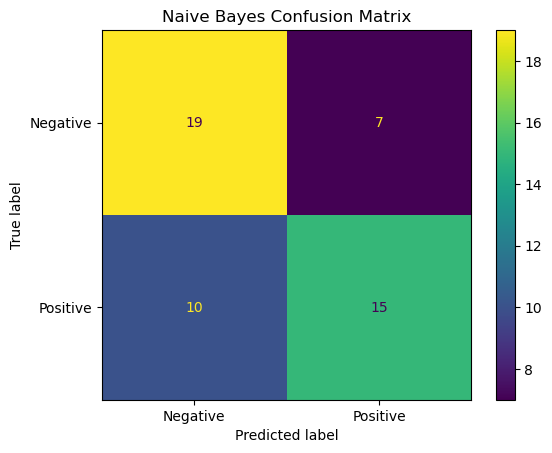


Logistic Regression
------------------------------
Accuracy: 0.6667
Precision: 0.6818
Recall: 0.6
F1 Score: 0.6383

Confusion Matrix:
[[19  7]
 [10 15]]


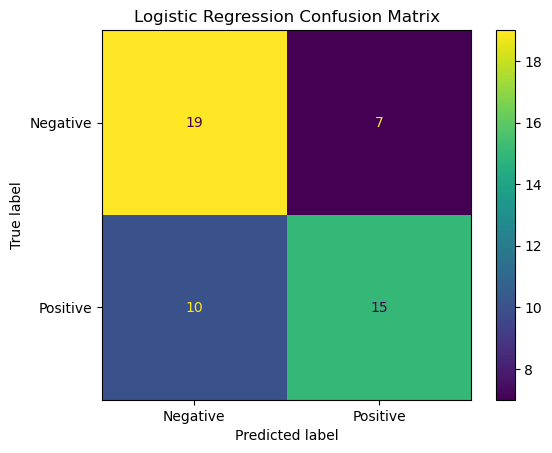


Model Comparison:
                     Accuracy  Precision  Recall  F1 Score
Naive Bayes            0.6667     0.6818     0.6    0.6383
Logistic Regression    0.6667     0.6818     0.6    0.6383

Best Model: Naive Bayes


In [9]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        pos_label="positive",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        pos_label="positive",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        pos_label="positive",
        zero_division=0
    )

    print(f"\n{model_name}")
    print("-" * 30)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=["negative", "positive"]
    )

    print("\nConfusion Matrix:")
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    display.plot(values_format="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }


# Evaluate Naive Bayes
nb_scores = evaluate_model(
    "Naive Bayes",
    y_test,
    nb_preds
)

lr_scores = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_preds
)


comparison = pd.DataFrame(
    [nb_scores, lr_scores],
    index=["Naive Bayes", "Logistic Regression"]
)

print("\nModel Comparison:")
print(comparison.round(4))

best_model_name = comparison["F1 Score"].idxmax()

print("\nBest Model:", best_model_name)

# Activity 5 — End-to-End Sentiment Analysis Pipeline

In [11]:
from sklearn.pipeline import Pipeline


if best_model_name == "Naive Bayes":
    chosen_model = MultinomialNB()
else:
    chosen_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", chosen_model)
])


pipeline.fit(X_train_text, y_train)

print("Pipeline trained successfully!")


new_reviews = [
    "This app is excellent and very easy to use.",
    "The app crashes constantly and is very frustrating.",
    "The app has useful features but needs improvement."
]

predictions = pipeline.predict(new_reviews)

print("\nSentiment Analysis Results:\n")

for i, (review, prediction) in enumerate(
    zip(new_reviews, predictions),
    start=1
):
    print(f"Review {i}: {review}")
    print(f"Predicted Sentiment: {prediction}")
    print()

probabilities = pipeline.predict_proba(new_reviews)
classes = pipeline.named_steps["classifier"].classes_

print("Prediction Probabilities:\n")

for review, probs in zip(new_reviews, probabilities):
    print("Review:", review)

    for sentiment, probability in zip(classes, probs):
        print(f"{sentiment}: {probability:.4f}")

    print()

Pipeline trained successfully!

Sentiment Analysis Results:

Review 1: This app is excellent and very easy to use.
Predicted Sentiment: negative

Review 2: The app crashes constantly and is very frustrating.
Predicted Sentiment: negative

Review 3: The app has useful features but needs improvement.
Predicted Sentiment: negative

Prediction Probabilities:

Review: This app is excellent and very easy to use.
negative: 0.5142
positive: 0.4858

Review: The app crashes constantly and is very frustrating.
negative: 0.6631
positive: 0.3369

Review: The app has useful features but needs improvement.
negative: 0.6508
positive: 0.3492

